# Review 2: Classification Models


In [1]:

print("Python kernel is working!")
print("Ready for Review 2")


Python kernel is working!
Ready for Review 2


In [2]:
import pandas as pd
import numpy as np

from pathlib import Path

# Find the Excel dataset in the project
possible_paths = [
    Path("../data/E Commerce Dataset.xlsx"),
    Path("../E Commerce Dataset.xlsx"),
    Path("../../E Commerce Dataset.xlsx"),
]

file_path = next((p for p in possible_paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        "Could not find 'E Commerce Dataset.xlsx'. "
        "Please check where the file is saved."
    )

df = pd.read_excel(file_path, sheet_name="E Comm")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate the target from the input features
target = "Churn"

X = df.drop(columns=[target, "CustomerID"], errors="ignore")
y = df[target]

# Identify numeric and categorical columns
numeric_columns = X.select_dtypes(include=["number"]).columns
categorical_columns = X.select_dtypes(exclude=["number"]).columns

# Preprocess numeric and categorical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Split data before fitting preprocessing to avoid data leakage
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit preprocessing only on training data
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Data preparation successful!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())


Data preparation successful!
Training features: (4504, 34)
Testing features: (1126, 34)

Training target distribution:
Churn
0    3746
1     758
Name: count, dtype: int64


In [4]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("RANDOM FOREST CLASSIFIER RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, rf_pred, average="weighted"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))


RANDOM FOREST CLASSIFIER RESULTS
----------------------------------------
Accuracy: 0.9822
Precision: 0.9337
Recall: 0.9632
Weighted F1-score: 0.9823
ROC-AUC: 0.9981

Confusion Matrix:
[[923  13]
 [  7 183]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.93      0.96      0.95       190

    accuracy                           0.98      1126
   macro avg       0.96      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [5]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Create and train the AdaBoost model
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

ada_model.fit(X_train, y_train)

# Make predictions
ada_pred = ada_model.predict(X_test)
ada_prob = ada_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("ADABOOST CLASSIFIER RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, ada_pred), 4))
print("Precision:", round(precision_score(y_test, ada_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, ada_pred, zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, ada_pred, average="weighted"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, ada_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ada_pred))

print("\nClassification Report:")
print(classification_report(y_test, ada_pred, zero_division=0))


ADABOOST CLASSIFIER RESULTS
----------------------------------------
Accuracy: 0.8801
Precision: 0.767
Recall: 0.4158
Weighted F1-score: 0.865
ROC-AUC: 0.8967

Confusion Matrix:
[[912  24]
 [111  79]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.97      0.93       936
           1       0.77      0.42      0.54       190

    accuracy                           0.88      1126
   macro avg       0.83      0.70      0.74      1126
weighted avg       0.87      0.88      0.86      1126



In [6]:

from sklearn.ensemble import GradientBoostingClassifier

# Create and train the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

# Make predictions
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("GRADIENT BOOSTING CLASSIFIER RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, gb_pred, zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, gb_pred, average="weighted"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

print("\nClassification Report:")
print(classification_report(y_test, gb_pred, zero_division=0))


GRADIENT BOOSTING CLASSIFIER RESULTS
----------------------------------------
Accuracy: 0.9147
Precision: 0.8092
Recall: 0.6474
Weighted F1-score: 0.9109
ROC-AUC: 0.945

Confusion Matrix:
[[907  29]
 [ 67 123]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       936
           1       0.81      0.65      0.72       190

    accuracy                           0.91      1126
   macro avg       0.87      0.81      0.83      1126
weighted avg       0.91      0.91      0.91      1126



In [7]:

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Create and train the Bagging model
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bag_model.fit(X_train, y_train)

# Make predictions
bag_pred = bag_model.predict(X_test)
bag_prob = bag_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("BAGGING CLASSIFIER RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, bag_pred), 4))
print("Precision:", round(precision_score(y_test, bag_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, bag_pred, zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, bag_pred, average="weighted"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, bag_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, bag_pred))

print("\nClassification Report:")
print(classification_report(y_test, bag_pred, zero_division=0))


BAGGING CLASSIFIER RESULTS
----------------------------------------
Accuracy: 0.9849
Precision: 0.9577
Recall: 0.9526
Weighted F1-score: 0.9849
ROC-AUC: 0.9978

Confusion Matrix:
[[928   8]
 [  9 181]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.96      0.95      0.96       190

    accuracy                           0.98      1126
   macro avg       0.97      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [8]:

from sklearn.neural_network import MLPClassifier

# Create and train the MLP model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=300,
    early_stopping=True,
    random_state=42
)

mlp_model.fit(X_train, y_train)

# Make predictions
mlp_pred = mlp_model.predict(X_test)
mlp_prob = mlp_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("MLP CLASSIFIER RESULTS")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, mlp_pred), 4))
print("Precision:", round(precision_score(y_test, mlp_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, mlp_pred, zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, mlp_pred, average="weighted"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, mlp_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, mlp_pred))

print("\nClassification Report:")
print(classification_report(y_test, mlp_pred, zero_division=0))


MLP CLASSIFIER RESULTS
----------------------------------------
Accuracy: 0.8943
Precision: 0.7795
Recall: 0.5211
Weighted F1-score: 0.8855
ROC-AUC: 0.8881

Confusion Matrix:
[[908  28]
 [ 91  99]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94       936
           1       0.78      0.52      0.62       190

    accuracy                           0.89      1126
   macro avg       0.84      0.75      0.78      1126
weighted avg       0.89      0.89      0.89      1126



In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Store the five Review 2 models and their predictions
models = {
    "Random Forest": (rf_pred, rf_prob),
    "AdaBoost": (ada_pred, ada_prob),
    "Gradient Boosting": (gb_pred, gb_prob),
    "Bagging": (bag_pred, bag_prob),
    "MLP": (mlp_pred, mlp_prob)
}

results = []

for model_name, (predictions, probabilities) in models.items():
    results.append({
        "Classifier": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

# Display scores rounded to four decimal places
display(
    comparison_df
    .sort_values(by="Weighted F1", ascending=False)
    .round(4)
    .reset_index(drop=True)
)


,Classifier,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Bagging,0.9849,0.9577,0.9526,0.9849,0.9978
1,Random Forest,0.9822,0.9337,0.9632,0.9823,0.9981
2,Gradient Boosting,0.9147,0.8092,0.6474,0.9109,0.9450
3,MLP,0.8943,0.7795,0.5211,0.8855,0.8881
4,AdaBoost,0.8801,0.7670,0.4158,0.8650,0.8967


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from scipy.sparse import issparse

# GaussianNB requires dense input
X_train_dense = X_train.toarray() if issparse(X_train) else X_train
X_test_dense = X_test.toarray() if issparse(X_test) else X_test

original_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

all_results = []

for name, model in original_models.items():
    if name == "Gaussian Naive Bayes":
        model.fit(X_train_dense, y_train)
        predictions = model.predict(X_test_dense)
        probabilities = model.predict_proba(X_test_dense)[:, 1]
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:, 1]

    all_results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# Add the five Review 2 classifiers
all_results.extend(results)

final_comparison_df = pd.DataFrame(all_results)

display(
    final_comparison_df
    .sort_values(by="Weighted F1", ascending=False)
    .round(4)
    .reset_index(drop=True)
)


c:\Users\P.S SHREE VIBIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Classifier,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Bagging,0.9849,0.9577,0.9526,0.9849,0.9978
1,Random Forest,0.9822,0.9337,0.9632,0.9823,0.9981
2,Decision Tree,0.9645,0.8866,0.9053,0.9646,0.9409
3,KNN,0.9227,0.8705,0.6368,0.9178,0.9476
4,Gradient Boosting,0.9147,0.8092,0.6474,0.9109,0.9450
5,SVM,0.9147,0.8917,0.5632,0.9067,0.9394
6,MLP,0.8943,0.7795,0.5211,0.8855,0.8881
7,Logistic Regression,0.8881,0.7424,0.5158,0.8797,0.8858
8,AdaBoost,0.8801,0.7670,0.4158,0.8650,0.8967
9,Gaussian Naive Bayes,0.7007,0.3220,0.7000,0.7358,0.7525


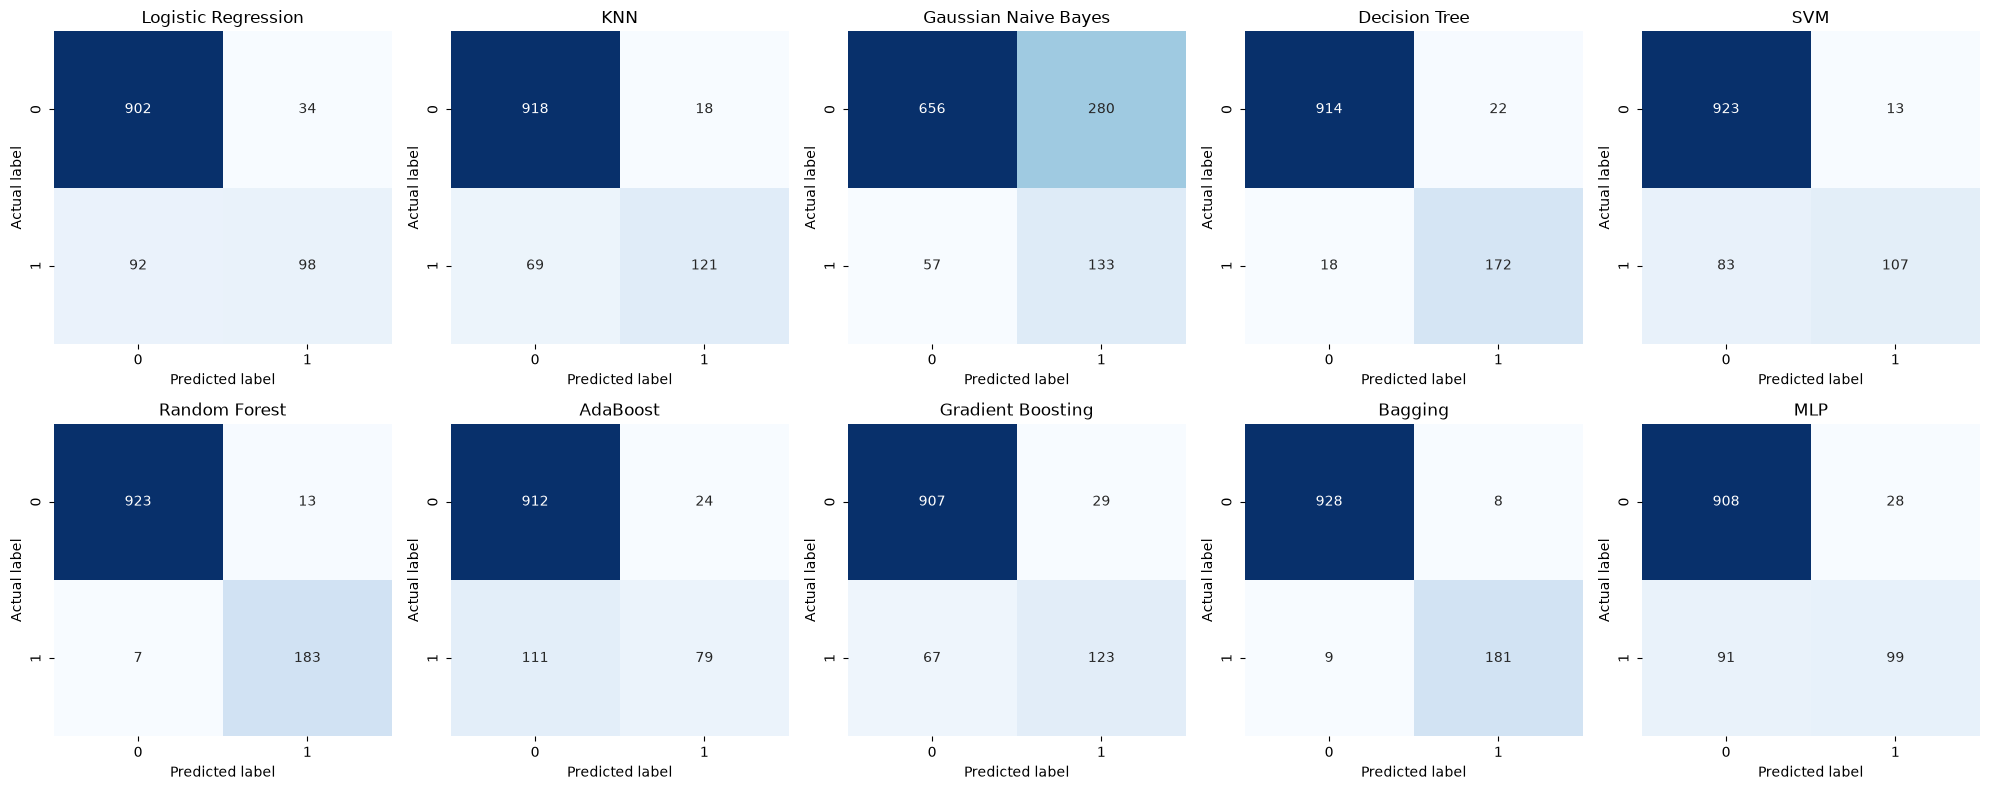

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predictions from the five original classifiers
original_predictions = {}

for name, model in original_models.items():
    if name == "Gaussian Naive Bayes":
        original_predictions[name] = model.predict(X_test_dense)
    else:
        original_predictions[name] = model.predict(X_test)

# Predictions from the five new classifiers
all_predictions = {
    **original_predictions,
    "Random Forest": rf_pred,
    "AdaBoost": ada_pred,
    "Gradient Boosting": gb_pred,
    "Bagging": bag_pred,
    "MLP": mlp_pred
}

# Plot all 10 confusion matrices
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (name, predictions) in zip(axes, all_predictions.items()):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()


In [12]:

# Identify the best classifier by weighted F1-score
best_row = final_comparison_df.loc[
    final_comparison_df["Weighted F1"].idxmax()
]

print("Best classifier:", best_row["Classifier"])
print("Weighted F1-score:", round(best_row["Weighted F1"], 4))


Best classifier: Bagging
Weighted F1-score: 0.9849


In [13]:

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score

# Train a baseline Decision Tree
baseline_tree = DecisionTreeClassifier(random_state=42)
baseline_tree.fit(X_train, y_train)

baseline_pred = baseline_tree.predict(X_test)
baseline_f1 = f1_score(
    y_test, baseline_pred, average="weighted"
)

# Tune the Decision Tree using cross-validation
param_grid = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Evaluate the tuned model
tuned_tree = grid_search.best_estimator_
tuned_pred = tuned_tree.predict(X_test)

tuned_f1 = f1_score(
    y_test, tuned_pred, average="weighted"
)
tuned_accuracy = accuracy_score(y_test, tuned_pred)

print("DECISION TREE TUNING RESULTS")
print("-" * 40)
print("Baseline weighted F1:", round(baseline_f1, 4))
print("Tuned weighted F1:", round(tuned_f1, 4))
print("Tuned accuracy:", round(tuned_accuracy, 4))
print("Best parameters:", grid_search.best_params_)

if tuned_f1 > baseline_f1:
    print("Result: Weighted F1 improved after tuning.")
elif tuned_f1 == baseline_f1:
    print("Result: Weighted F1 stayed the same.")
else:
    print("Result: Weighted F1 decreased; report the actual result.")


DECISION TREE TUNING RESULTS
----------------------------------------
Baseline weighted F1: 0.9646
Tuned weighted F1: 0.9744
Tuned accuracy: 0.9742
Best parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Result: Weighted F1 improved after tuning.


### Why Decision Tree Was Selected for Hyperparameter Tuning

Although the Bagging Classifier achieved the highest weighted F1-score among the evaluated models, the Decision Tree Classifier was selected for hyperparameter tuning because it is easy to interpret and explain. Its decision rules can be visualized, making it useful for understanding the factors that influence customer churn predictions.

The baseline Decision Tree achieved a weighted F1-score of **0.9646**. GridSearchCV with 5-fold cross-validation was used to find better hyperparameters. After tuning, the weighted F1-score increased to **0.9744**, demonstrating an improvement of **0.0098** (0.98 percentage points), with a test accuracy of **0.9742**.

Therefore, Decision Tree was selected to demonstrate the effect of hyperparameter tuning while maintaining model interpretability. Bagging remained the best-performing model according to weighted F1-score in the overall comparison.

### Hyperparameter Tuning and Model Improvement

A Decision Tree Classifier was tuned using GridSearchCV with 5-fold cross-validation. The search evaluated different values of maximum depth, minimum samples per split, minimum samples per leaf, and splitting criterion.

The baseline Decision Tree achieved a weighted F1-score of 0.9646. After tuning, the weighted F1-score increased to 0.9744, while the tuned model achieved an accuracy of 0.9742. This represents an improvement of 0.0098 in weighted F1-score.

The best parameters selected by GridSearchCV were `criterion='entropy'`, `max_depth=None`, `min_samples_leaf=1`, and `min_samples_split=2`. The results demonstrate that hyperparameter tuning improved the weighted F1-score on the test set.